# DBSCAN

## 군집 대상과 입력

- 공원의 방문 위치가 두 굽은 산책로를 따라 모이면 하나의 중심(centroid)만으로 각 집단을 표현하기 어렵다.
- DBSCAN(Density-Based Spatial Clustering of Applications with Noise)은 조밀한 이웃(neighborhood)을 연결하여 군집(cluster)을 만드는 밀도 기반 클러스터링(density-based clustering) 알고리즘이다.
- 입력은 두 곡선 주변의 위치 300개로 이루어진 합성 데이터(synthetic data)이다. 각 좌표를 표준화(standardization)한 뒤 거리를 계산하며, 생성 과정의 정답 라벨(label)은 사용하지 않는다.
- 이웃 반경(neighborhood radius)과 최소 관측 수(minimum number of samples)를 정하면 군집 수가 결과로 나온다. $K$를 미리 지정하지 않으며 일부 관측은 잡음(noise)으로 남는다.

## 이웃과 점의 유형

### 이웃 반경과 밀도 조건

- 관측(observation) $\mathbf{x}_i$의 이웃(neighborhood)은 거리가 $\varepsilon$ 이하인 관측의 집합이다.

  $\displaystyle N_{\varepsilon}(\mathbf{x}_i)=\{\mathbf{x}_j:\|\mathbf{x}_j-\mathbf{x}_i\|_2\leq\varepsilon\}.$

- $\varepsilon$는 ‘eps’이며 이 예제에서는 표준화한 좌표의 거리이다. 자기 자신과의 거리는 0이므로 이웃 수에 자신도 포함한다.
- 핵심점(core point)은 이웃 수가 ‘min_samples’ 이상인 관측이다.

  $\displaystyle |N_{\varepsilon}(\mathbf{x}_i)|\geq\texttt{min\_samples}.$

- $|N_{\varepsilon}(\mathbf{x}_i)|$는 이웃의 개수이다. 최소 관측 수가 5이면 자신과 다른 관측 4개 이상이 필요하다. 군집 전체의 크기를 지정하는 조건은 아니다.

### 핵심점·경계점·잡음

- 경계점(border point)은 핵심점은 아니지만 핵심점의 이웃에 속하는 관측이다.
- 잡음점(noise point)은 핵심점도 아니고 어떤 핵심점의 이웃에도 속하지 않는 관측이다. 점의 유형은 반경과 최소 관측 수에 따라 달라진다.

  <img src="https://raw.githubusercontent.com/sonamu-jun/introduction-to-ai-convergence/main/10-1_Clustering/assets/03_density_neighborhoods.png" alt="같은 여덟 점에서 이웃 수로 구분한 핵심점·경계점·잡음" width="512" style="max-width:100%;height:auto;">


## 핵심점을 통한 군집 확장

- 핵심점에서 시작해 이웃을 모으고, 그중 다른 핵심점이 있으면 그 점의 이웃도 추가한다. 핵심점을 통해 더 이어질 곳이 없을 때 하나의 군집이 완성된다.
- 경계점은 군집에 들어가지만 확장을 이어 가지 않는다. 그림의 F는 핵심점 C·D와 가까워 군집에 속하지만, G는 경계점 F와 가깝다는 이유만으로 같은 군집이 되지 않는다.
- 아직 방문하지 않은 핵심점에서는 다른 군집을 시작한다. 처음 잡음 후보였던 점도 나중에 핵심점의 이웃으로 발견되면 경계점이 될 수 있다.
- 핵심점의 이웃이 사슬처럼 이어지면 긴 곡선 모양의 군집도 형성된다. ‘eps’는 군집 전체의 지름을 제한하지 않는다.

## 단계별 군집 확장

- DBSCAN은 중심을 반복 갱신하는 최적화가 아니라, 밀도 조건을 만족하는 이웃을 연결하는 과정이다. 이 예제는 너비 우선 탐색(breadth-first search)으로 연결된 핵심점을 차례로 확장한다.
- frontier는 이번 단계에서 이웃을 검사하는 핵심점들의 집합이다. 한 Step에서 이 점들의 이웃을 군집에 넣고, 아직 확장하지 않은 핵심점을 다음 frontier로 넘긴다.
- 회색 점은 아직 군집에 배정되지 않은 관측이다. 주황색 테두리는 현재 frontier이다. 주황색 별과 점선 원은 그중 핵심점 하나와 실제 이웃 반경을 나타낸다. 검은 테두리는 이번 단계에서 새로 배정된 관측이다.
- 색이 채워진 점은 배정된 핵심점이고 빈 점은 배정된 경계점이다. 경계점은 다음 frontier에 들어가지 않으므로 그 점을 통해 확장하지 않는다.
- 한 군집의 frontier가 비면 아직 배정하지 않은 다른 핵심점에서 다음 군집을 시작한다. 모든 확장이 끝난 뒤 남은 관측을 잡음으로 표시한다.

  <img src="https://raw.githubusercontent.com/sonamu-jun/introduction-to-ai-convergence/main/10-1_Clustering/assets/03_cluster_expansion.png" alt="두 곡선을 따라 핵심점의 이웃이 단계적으로 연결되는 DBSCAN 과정" width="512" style="max-width:100%;height:auto;">

## 단계와 밀도 조건의 변화

- ‘Step’은 실제 확장 단계를 선택하고 ‘Previous’·‘Next’는 한 단계씩 이동한다. ‘Finish’는 모든 군집 확장과 잡음 판정을 마친 결과를 표시한다.
- 기본값 `eps=0.30`, `min_samples=10`은 군집별로 18단계씩 확장하고 마지막 잡음 판정을 포함해 37단계이다. 완료 시 군집 2개, 핵심점 251개, 경계점 47개, 잡음점 2개가 생긴다.
- ‘eps’와 ‘min_samples’를 바꾸면 같은 관측으로 확장 과정을 다시 계산하고 0단계에서 시작한다. 점의 위치와 축 범위는 고정하며 가로·세로축의 거리 비율은 같다.
- ‘eps’를 줄이면 집단이 나뉘거나 잡음이 늘 수 있고, 키우면 떨어진 집단이 연결될 수 있다. 최소 관측 수를 늘리면 핵심점 조건이 엄격해진다.
- 중간 단계의 회색 점은 아직 남은 관측이며 잡음으로 확정된 점이 아니다. ‘Assigned’와 ‘New’는 현재까지 배정된 관측 수와 이번 단계에서 새로 배정된 수이다.


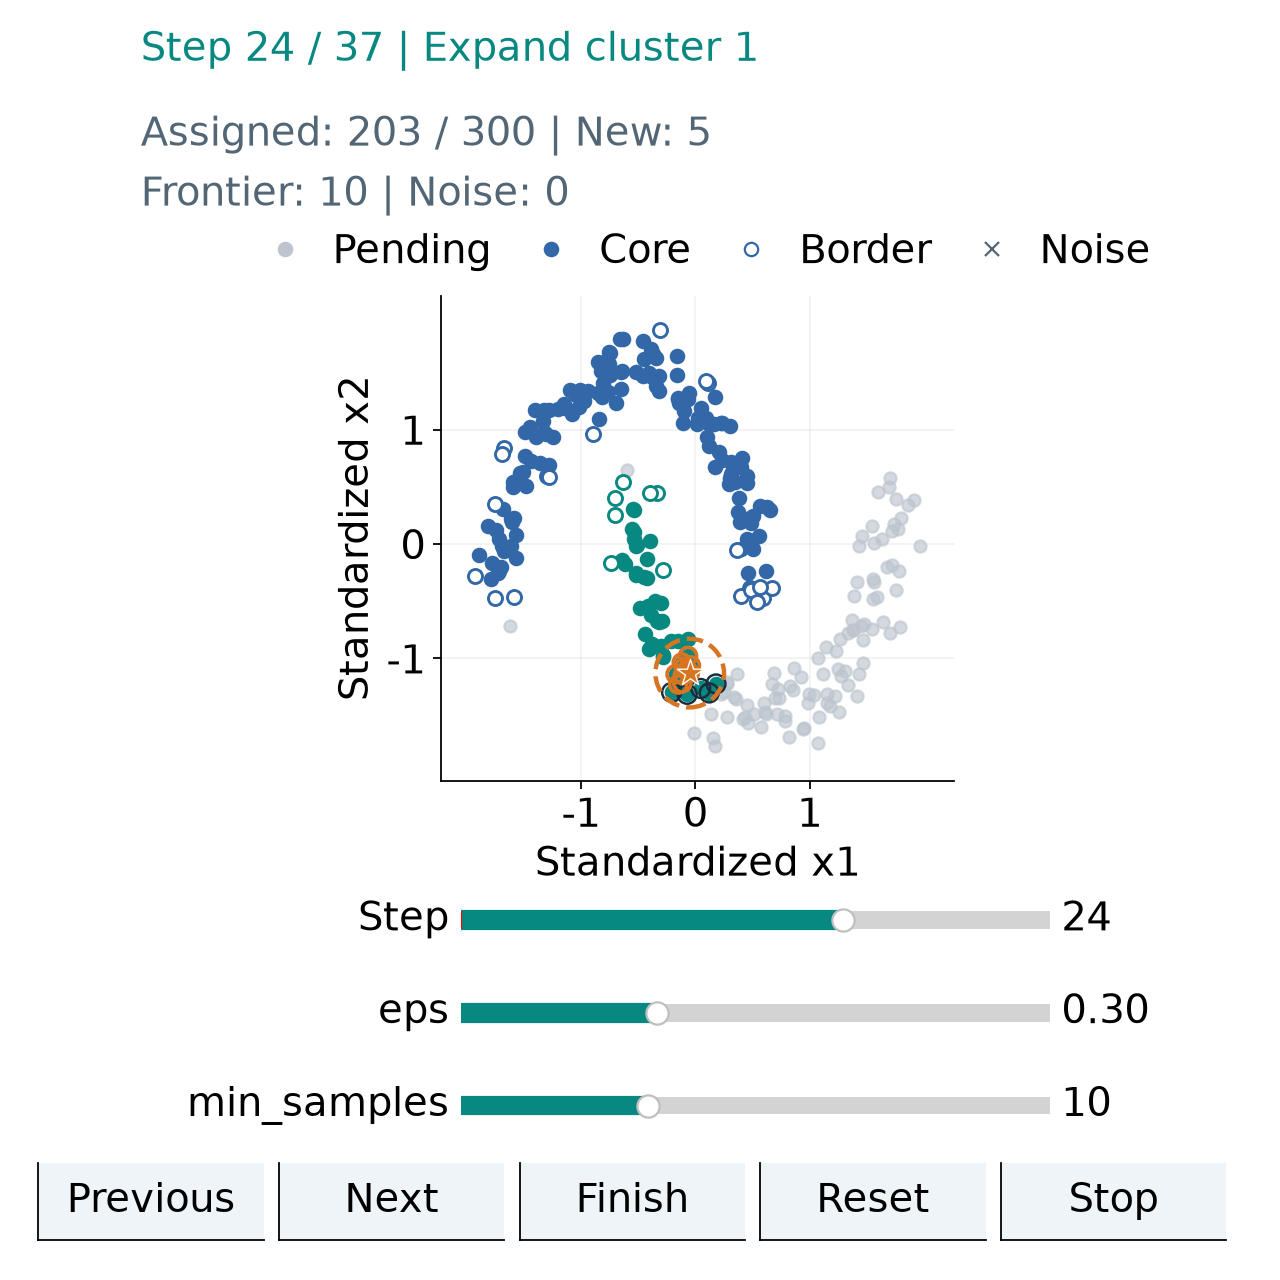

In [1]:
import os
import sys
import io
import numpy as np
import matplotlib

CLUSTERING_STATIC = os.environ.get("CLUSTERING_STATIC") == "1"
CLUSTERING_BROWSER = sys.platform == "emscripten"
if not CLUSTERING_STATIC and not CLUSTERING_BROWSER:
    from IPython import get_ipython
    shell = get_ipython()
    if shell is not None and getattr(shell, "kernel", None) is not None:
        shell.run_line_magic("matplotlib", "widget")

import matplotlib.pyplot as plt
from matplotlib.widgets import Slider, Button
from IPython.display import Image, display

plt.rcParams.update({
    "font.size": 18, "axes.labelsize": 18,
    "xtick.labelsize": 18, "ytick.labelsize": 18, "legend.fontsize": 18,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": .16, "lines.linewidth": 2.5,
    "axes.unicode_minus": False, "figure.facecolor": "white",
})
BLUE, TEAL, ORANGE, PURPLE = "#3268a8", "#078880", "#d87522", "#8251ac"


for _previous_view in globals().get("_clustering_views", {}).values():
    _previous_view.close()
_clustering_views = {}


class ClusteringExplorer:

    def __init__(self, name, render, sliders, actions=()):
        self.render = render
        self.slider_specs = sliders
        self.controls, self.buttons, self.state = {}, {}, {}
        self.stopped = False
        self.defaults = {key: initial for key, label, low, high, initial, step, fmt in sliders}
        with plt.ioff():
            height = min(8.0, 6.8 + .58 * len(sliders))
            self.figure = plt.figure(figsize=(8, height), dpi=64)
        self.status = self.figure.text(.11, 1 - .38 / height, "", fontsize=18, color=TEAL)
        self.detail = self.figure.text(.11, 1 - .66 / height, "", va="top", fontsize=18, color="#536675", linespacing=1.5)
        bottom = (1.38 + .58 * len(sliders)) / height
        top = 1 - 1.85 / height
        self.plot_bottom = bottom
        self.ax = self.figure.add_axes([.14, bottom, .81, top - bottom])
        for i, (key, label, low, high, initial, step, fmt) in enumerate(sliders):
            y = (.98 + .58 * (len(sliders) - i - 1)) / height
            slider = Slider(self.figure.add_axes([.36, y, .46, .22 / height]),
                            label, low, high, valinit=initial, valstep=step,
                            valfmt=fmt, color=TEAL)
            slider.label.set_fontsize(18)
            slider.valtext.set_fontsize(18)
            slider.on_changed(self.update)
            self.controls[key] = slider
        commands = list(actions) + [("Reset", lambda view: view.reset()),
                                    ("Stop", lambda view: view.stop())]
        self.commands = commands
        width = min(.25, .94 / len(commands) - .012)
        for i, (label, callback) in enumerate(commands):
            button = Button(self.figure.add_axes([.03 + i * (width + .012), .25 / height, width, .48 / height]),
                            label,
                            color="#eef4f7", hovercolor="#d7e9e6")
            button.label.set_fontsize(18)
            button.on_clicked(lambda event, cb=callback: cb(self) if not self.stopped else None)
            self.buttons[label] = button
        self.connections = [self.figure.canvas.mpl_connect("close_event", lambda event: self.stop())]
        _clustering_views[name] = self
        self.update()

    def update(self, _=None):
        if self.stopped:
            return
        self.ax.clear()
        self.state = self.render(self, **{key: slider.val for key, slider in self.controls.items()})
        self.figure.canvas.draw_idle()
        self.refresh_local()

    def set_values(self, **values):
        if self.stopped:
            return
        for key, value in values.items():
            slider = self.controls[key]
            events, drawing = slider.eventson, slider.drawon
            slider.eventson = slider.drawon = False
            slider.set_val(value)
            slider.eventson, slider.drawon = events, drawing
        self.update()

    def reset(self):
        self.set_values(**self.defaults)

    def refresh_local(self):
        if not hasattr(self, "local_image"):
            return
        from matplotlib.transforms import Bbox
        width, height = self.figure.get_size_inches()
        self.figure.canvas.draw()
        bounds = self.ax.get_tightbbox(self.figure.canvas.get_renderer())
        lower = max(0, bounds.y0 / self.figure.dpi - .04)
        buffer = io.BytesIO()
        self.figure.savefig(buffer, format="png", dpi=64, facecolor="white",
                            bbox_inches=Bbox.from_extents(0, lower, width, height))
        self.local_image.value = buffer.getvalue()
        self.syncing_local = True
        for key, control in self.local_controls.items():
            source = self.controls[key]
            if control.value > source.valmax:
                control.value = source.valmax
            control.max = source.valmax
            control.value = source.val
        self.syncing_local = False

    def start_local(self):
        from ipywidgets import Image as WidgetImage, FloatSlider, IntSlider
        from ipywidgets import Button as WidgetButton, HBox, VBox, Layout
        self.syncing_local = False
        self.local_image = WidgetImage(format="png", layout=Layout(
            width="100%", max_width="512px", height="auto"))
        self.local_controls, self.local_buttons = {}, {}
        for key, label, low, high, initial, step, fmt in self.slider_specs:
            slider_type = IntSlider if fmt == "%0.0f" and step == 1 else FloatSlider
            control = slider_type(value=self.controls[key].val, min=low, max=self.controls[key].valmax, step=step,
                                  description=label, readout_format=fmt.replace("%0", ""),
                                  continuous_update=True,
                                  style={"description_width": "130px"},
                                  layout=Layout(width="100%", max_width="512px"))
            def changed(change, key=key):
                if not self.syncing_local and not self.stopped:
                    self.controls[key].set_val(change["new"])
            control.observe(changed, names="value")
            self.local_controls[key] = control
        for label, callback in self.commands:
            button = WidgetButton(description=label, layout=Layout(
                flex="1 1 0", min_width="120px", height="34px", margin="2px"))
            button.on_click(lambda _, cb=callback: cb(self) if not self.stopped else None)
            self.local_buttons[label] = button
        row = HBox(list(self.local_buttons.values()), layout=Layout(width="100%", flex_flow="row wrap"))
        self.local_row = row
        self.local_output = VBox([self.local_image, *self.local_controls.values(), row],
                                layout=Layout(width="100%", max_width="512px"))
        self.refresh_local()
        display(self.local_output)

    def start(self):
        if CLUSTERING_STATIC:
            buffer = io.BytesIO()
            self.figure.savefig(buffer, format="png", dpi=160, facecolor="white")
            display(Image(data=buffer.getvalue(), width=512,
                          alt=self.status.get_text() + ". " + self.detail.get_text()))
            plt.close(self.figure)
        elif CLUSTERING_BROWSER:
            plt.show(block=False)
        elif hasattr(self.figure.canvas, "toolbar_visible"):
            self.start_local()
        else:
            plt.show(block=False)

    def stop(self):
        if self.stopped:
            return
        self.stopped = True
        for control in list(self.controls.values()) + list(self.buttons.values()):
            control.set_active(False)
        for control in [*getattr(self, "local_controls", {}).values(),
                        *getattr(self, "local_buttons", {}).values()]:
            control.disabled = True
        if hasattr(self, "local_buttons"):
            self.local_buttons["Stop"].description = "Stopped"
        self.buttons["Stop"].label.set_text("Stopped")
        self.figure.canvas.draw_idle()
        self.refresh_local()

    def close(self):
        self.stop()
        for connection in self.connections:
            self.figure.canvas.mpl_disconnect(connection)
        for control in list(self.controls.values()) + list(self.buttons.values()):
            control.disconnect_events()
        plt.close(self.figure)
        if hasattr(self, "local_output"):
            self.local_output.close()
            self.local_image.close()
            self.local_row.close()
            for control in [*self.local_controls.values(), *self.local_buttons.values()]:
                control.close()


from matplotlib.lines import Line2D
from matplotlib.patches import Circle
from sklearn.datasets import make_moons
from sklearn.preprocessing import StandardScaler

X_raw, _ = make_moons(n_samples=300, noise=.08, random_state=42)
X = StandardScaler().fit_transform(X_raw)
bounds = (X[:, 0].min() - .3, X[:, 0].max() + .3,
          X[:, 1].min() - .3, X[:, 1].max() + .3)


def build_dbscan_states(points, eps, min_samples):
    distances = np.sum((points[:, None, :] - points[None, :, :]) ** 2, axis=2)
    neighbors = distances <= eps ** 2
    core = neighbors.sum(axis=1) >= min_samples
    labels = np.full(len(points), -2, dtype=int)
    expanded = np.zeros(len(points), dtype=bool)
    empty = np.array([], dtype=int)
    states = [dict(phase="initial", labels=labels.copy(), expanded=expanded.copy(),
                   frontier=empty, added=empty, cluster=-1)]
    cluster = 0
    for seed in np.argsort(points[:, 0], kind="stable"):
        if not core[seed] or labels[seed] >= 0:
            continue
        frontier = np.array([seed], dtype=int)
        while len(frontier):
            reached = neighbors[frontier].any(axis=0)
            added = np.flatnonzero(reached & (labels == -2))
            labels[added] = cluster
            expanded[frontier] = True
            states.append(dict(phase="expand", labels=labels.copy(), expanded=expanded.copy(),
                               frontier=frontier.copy(), added=added, cluster=cluster))
            frontier = np.flatnonzero(reached & core & ~expanded)
        cluster += 1
    labels[labels == -2] = -1
    states.append(dict(phase="complete", labels=labels.copy(), expanded=expanded.copy(),
                       frontier=empty, added=empty, cluster=-1))
    return {"states": states, "core": core, "neighbors": neighbors,
            "eps": eps, "min_samples": min_samples, "clusters": cluster}


default_trace = build_dbscan_states(X, .30, 10)


def render_dbscan(view, step, eps, min_samples):
    key = (round(float(eps), 2), int(min_samples))
    if getattr(view, "trace_key", None) != key:
        view.trace = default_trace if key == (.30, 10) else build_dbscan_states(X, *key)
        view.trace_key = key
        step = 0
    trace = view.trace
    history = trace["states"]
    control = view.controls["step"]
    control.valmax = len(history) - 1
    control.ax.set_xlim(0, control.valmax)
    step = int(np.clip(step, 0, control.valmax))
    events, drawing = control.eventson, control.drawon
    control.eventson = control.drawon = False
    control.set_val(step)
    control.eventson, control.drawon = events, drawing
    state = history[step]
    labels, core = state["labels"], trace["core"]
    pending, noise = labels == -2, labels == -1
    ids = sorted(set(labels[labels >= 0]))
    palette = [BLUE, TEAL, PURPLE, ORANGE]
    if trace["clusters"] > len(palette):
        palette = plt.cm.turbo(np.linspace(.06, .94, trace["clusters"]))
    ax = view.ax
    ax.scatter(X[pending, 0], X[pending, 1], s=30, color="#bcc5ce", alpha=.65, zorder=2)
    for cluster in ids:
        color = palette[cluster]
        members = labels == cluster
        filled, hollow = members & core, members & ~core
        ax.scatter(X[filled, 0], X[filled, 1], s=36, color=color, zorder=3)
        ax.scatter(X[hollow, 0], X[hollow, 1], s=40, facecolors="white",
                   edgecolors=[color], linewidths=1.3, zorder=3)
    ax.scatter(X[noise, 0], X[noise, 1], s=45, marker="x", color="#536675", zorder=3)
    added, frontier = state["added"], state["frontier"]
    ax.scatter(X[added, 0], X[added, 1], s=72, facecolors="none",
               edgecolors="#172d3e", linewidths=1.1, zorder=4)
    ax.scatter(X[frontier, 0], X[frontier, 1], s=60, facecolors="none",
               edgecolors=ORANGE, linewidths=1.6, zorder=5)
    representative = None
    if len(frontier):
        representative = int(frontier[len(frontier) // 2])
        point = X[representative]
        ax.add_patch(Circle(point, eps, fill=False, color=ORANGE,
                            linestyle="--", linewidth=2, zorder=5))
        ax.scatter(*point, marker="*", s=155, color=ORANGE,
                   edgecolors="white", linewidths=.6, zorder=6)
    ax.set(xlim=bounds[:2], ylim=bounds[2:], xticks=[-1, 0, 1], yticks=[-1, 0, 1],
           xlabel="Standardized x1", ylabel="Standardized x2")
    ax.set_aspect("equal", adjustable="box")
    ax.legend(handles=[
        Line2D([], [], marker="o", linestyle="", color="#bcc5ce", label="Pending"),
        Line2D([], [], marker="o", linestyle="", color=BLUE, label="Core"),
        Line2D([], [], marker="o", linestyle="", markerfacecolor="white", markeredgecolor=BLUE, label="Border"),
        Line2D([], [], marker="x", linestyle="", color="#536675", label="Noise"),
    ], loc="lower center", bbox_to_anchor=(.5, 1.015), ncol=4,
              frameon=False, borderaxespad=0, handletextpad=.2, columnspacing=.5)
    phase = ("Ready to expand" if state["phase"] == "initial" else "Complete"
             if state["phase"] == "complete" else f"Expand cluster {state['cluster']}")
    view.status.set_text(f"Step {step} / {len(history)-1} | {phase}")
    view.detail.set_text(f"Assigned: {np.sum(labels >= 0)} / {len(X)} | New: {len(added)}\n"
                         f"Frontier: {len(frontier)} | Noise: {noise.sum()}")
    return dict(state, step=step, core=core, pending=pending, noise=noise,
                border=(labels >= 0) & ~core, clusters=len(ids), eps=eps, representative=representative)


def move_dbscan_step(view, offset):
    final = len(view.trace["states"]) - 1
    view.set_values(step=int(np.clip(view.controls["step"].val + offset, 0, final)))


dbscan_view = ClusteringExplorer("dbscan", render_dbscan, [
    ("step", "Step", 0, len(default_trace["states"]) - 1, 0, 1, "%0.0f"),
    ("eps", "eps", .10, .70, .30, .01, "%0.2f"),
    ("min_samples", "min_samples", 3, 25, 10, 1, "%0.0f"),
], actions=[
    ("Previous", lambda view: move_dbscan_step(view, -1)),
    ("Next", lambda view: move_dbscan_step(view, 1)),
    ("Finish", lambda view: view.set_values(step=len(view.trace["states"]) - 1)),
])
if CLUSTERING_STATIC:
    dbscan_view.set_values(step=24)
dbscan_view.start()


## 밀도 기준과 적용 한계

- 군집마다 밀도(density)가 크게 다르면 하나의 반경으로 조밀한 집단과 성긴 집단을 함께 구분하기 어렵다. 특징(feature)이 많아지면 거리 자체의 구별력이 약해질 수도 있다.
- 표준화는 각 좌표의 상대적 거리를 바꾼다. 실제 공간의 길이가 중요하다면 같은 단위의 원래 좌표를 사용하는 선택도 고려해야 한다.
- 잡음 라벨 `-1`은 선택한 밀도 규칙으로 군집에 속하지 않았다는 뜻이다. 관측 오류나 현실의 이상 현상을 증명하지 않는다.
- 군집 번호에는 순서가 없다. 관측 순서를 바꾸면 번호뿐 아니라 두 핵심 영역에 함께 닿는 경계점의 소속도 바뀔 수 있다.
- DBSCAN은 입력한 관측에 라벨을 부여하는 알고리즘이다. scikit-learn의 DBSCAN도 새 관측에 대한 일반적인 `predict` 메서드를 제공하지 않는다. 새 점을 처리하려면 별도의 규칙이나 재학습이 필요하다.
